# Visualize Numerical-Token Subgraph Diagnostics

This Visualize notebook loads the cached data produced by `Generate-numeric-token-layer-averaged-diagnostics-across-context-lengths.ipynb` and shows layer-averaged graph-spectral diagnostics across context lengths for numerical-token subgraphs using Llama-3.2-3B, as presented under **Additional Controls and Higher-Dimensional Inputs** in the appendix.

The original prompts are retained during inference; the analyzed graph and hidden-state signal are restricted to numerical-token positions. Selected edge weights are preserved, and degrees and Laplacians are recomputed without further attention normalization. The broad qualitative trends persist with weaker separation among input families, supporting robustness to excluding separator tokens from the analyzed graph.

The panels show normalized Fiedler value, high-frequency energy ratio (HFER), and effective active modes. Curves show means across realizations after averaging over layers; shaded bands show standard deviations across realizations.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox
from matplotlib.ticker import FormatStrFormatter, MaxNLocator


In [2]:
DATA_PATH = Path("cache") / "numeric_only_diagnostics_averaged_over_layers_vs_context_length_20_runs.npz"

# Load labels, context lengths, and realization summaries
with np.load(DATA_PATH, allow_pickle=False) as data:
    input_names = data["input_names"].astype(str)
    context_token_counts = data["context_token_counts"].astype(int)
    num_realizations = int(data["num_ensemble_runs"])
    if str(data["model_name"]) != "meta-llama/Llama-3.2-3B" or int(data["num_layers"]) != 28:
        raise ValueError("Expected the Llama-3.2-3B layer-averaged cache.")
    if num_realizations != 20 or len(input_names) != 10 or len(context_token_counts) != 20:
        raise ValueError("The cached study does not match the expected full sweep.")
    if "completed_mask" in data and not data["completed_mask"].all():
        raise ValueError("The cached sweep is incomplete.")

    # Means and sample standard deviations across realizations
    active_modes_mean = data["numeric_active_modes_mean"].astype(float)
    active_modes_std = data["numeric_active_modes_std"].astype(float)
    fiedler_mean = data["numeric_fiedler_mean"].astype(float)
    fiedler_std = data["numeric_fiedler_std"].astype(float)
    hfer_mean = data["numeric_hfer_mean"].astype(float)
    hfer_std = data["numeric_hfer_std"].astype(float)

# Validate plotting arrays before drawing the figure
expected_shape = (len(input_names), len(context_token_counts))
for mean, std in ((active_modes_mean, active_modes_std), (fiedler_mean, fiedler_std), (hfer_mean, hfer_std)):
    if mean.shape != expected_shape or std.shape != expected_shape:
        raise ValueError("Unexpected diagnostic summary shape.")
    if not np.isfinite(mean).all() or not np.isfinite(std).all() or (std < 0).any():
        raise ValueError("Expected finite means and nonnegative standard deviations.")
if not np.all(np.diff(context_token_counts) > 0):
    raise ValueError("Context lengths must increase strictly.")


In [3]:
def _diagnostic_line_style(data_name):
    # Use consistent styles across diagnostics
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    # Draw chaotic and Lorenz curves above periodic curves
    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2

    style["markersize"] = 4.0
    return style


Saved figures/numeric_only_layer_averaged_combined_diagnostics.pdf


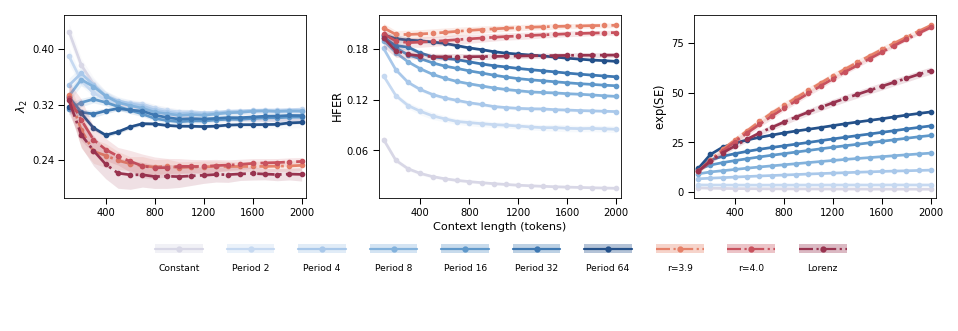

In [4]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
COMBINED_FIGURE_PATH = FIGURE_DIR / "numeric_only_layer_averaged_combined_diagnostics.pdf"

x = context_token_counts.astype(float)


def _finite_value_limits(values, padding_fraction=0.05):
    # Pad finite data ranges to set axis limits
    finite_values = np.asarray(values, dtype=float)
    finite_values = finite_values[np.isfinite(finite_values)]
    if finite_values.size == 0:
        return None

    value_min = float(np.min(finite_values))
    value_max = float(np.max(finite_values))
    value_span = value_max - value_min
    if value_span <= 0:
        padding = max(abs(value_min) * padding_fraction, padding_fraction)
    else:
        padding = value_span * padding_fraction
    return value_min - padding, value_max + padding


def _diagnostic_y_limits(mean, std):
    # Include the uncertainty bands when setting y-axis limits
    mean = np.asarray(mean, dtype=float)
    std = np.asarray(std, dtype=float)
    return _finite_value_limits(np.concatenate([(mean - std).ravel(), (mean + std).ravel()]))


def _plot_context_diagnostic(ax, mean, std):
    # Plot realization means with one-standard-deviation bands
    for input_idx, data_name in enumerate(input_names):
        y = mean[input_idx].astype(float)
        band = std[input_idx].astype(float)
        style = _diagnostic_line_style(str(data_name))
        zorder = style.get("zorder", 2)
        ax.plot(
            x,
            y,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.3,
            marker=style["marker"],
            markersize=1.7,
            zorder=zorder,
        )
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.15,
            linewidth=0,
            zorder=max(zorder - 0.5, 0),
        )


def _format_combined_axis(ax, ylabel):
    ax.set_ylabel(ylabel, labelpad=1, fontsize=5.6)
    x_limits = _finite_value_limits(x, padding_fraction=0.02)
    if x_limits is not None:
        ax.set_xlim(*x_limits)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)


def _format_diagnostic_y_axis(ax, mean, std, formatter=None, integer_ticks=False):
    y_limits = _diagnostic_y_limits(mean, std)
    if y_limits is not None:
        ax.set_ylim(*y_limits)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=integer_ticks))
    if formatter is not None:
        ax.yaxis.set_major_formatter(formatter)


# Order input families by dynamical complexity
complexity_legend_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _complexity_legend_rows(data_name):
    label_map = {
        "Constant sampled": ("Constant", ""),
        "Logistic r=3.2": ("Period 2", ""),
        "Logistic r=3.5": ("Period 4", ""),
        "Logistic r=3.55": ("Period 8", ""),
        "Logistic r=3.566": ("Period 16", ""),
        "Logistic r=3.5692": ("Period 32", ""),
        "Logistic r=3.5698": ("Period 64", ""),
        "Logistic r=3.9": ("r=3.9", ""),
        "Logistic r=4.0": ("r=4.0", ""),
        "Lorenz": ("Lorenz", ""),
    }
    return label_map.get(str(data_name), (str(data_name), ""))


def _add_complexity_strip_legend(fig):
    ordered_names = [name for name in complexity_legend_order if name in set(input_names.astype(str))]
    ax_leg = fig.add_axes([0.075, 0.130, 0.910, 0.185])
    ax_leg.set_xlim(-0.55, len(ordered_names) - 0.45)
    ax_leg.set_ylim(0.0, 1.0)
    ax_leg.axis("off")

    spacing_scale = 0.84
    swatch_half_width = 0.28
    swatch_height = 0.115
    legend_center = 0.5 * (len(ordered_names) - 1)

    def _legend_x(raw_x):
        return legend_center + spacing_scale * (float(raw_x) - legend_center)

    for idx, data_name in enumerate(ordered_names):
        legend_x = _legend_x(idx)
        style = _diagnostic_line_style(str(data_name))
        ax_leg.add_patch(
            Rectangle(
                (legend_x - swatch_half_width, 0.7850),
                2.0 * swatch_half_width,
                swatch_height,
                facecolor=style["color"],
                edgecolor="none",
                alpha=0.34,
            )
        )
        ax_leg.plot(
            [legend_x - swatch_half_width, legend_x + swatch_half_width],
            [0.8425, 0.8425],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.05,
            solid_capstyle="round",
        )
        ax_leg.plot(legend_x, 0.8425, marker=style["marker"], markersize=2.0, color=style["color"])
        top_label, bottom_label = _complexity_legend_rows(data_name)
        ax_leg.text(legend_x, 0.605, top_label, ha="center", va="center", fontsize=4.4)
        if bottom_label:
            ax_leg.text(legend_x, 0.505, bottom_label, ha="center", va="center", fontsize=4.4)

with plt.rc_context({
    "font.size": 7.6,
    "axes.labelsize": 5.4,
    "axes.titlesize": 6.0,
    "xtick.labelsize": 4.8,
    "ytick.labelsize": 4.8,
    "legend.fontsize": 7.6,
    "axes.linewidth": 0.4,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig = plt.figure(figsize=(6.30, 2.87), dpi=300)
    gs = fig.add_gridspec(
        1,
        3,
        left=0.068,
        right=0.990,
        top=0.830,
        bottom=0.405,
        wspace=0.30,
    )

    ax_fiedler = fig.add_subplot(gs[0, 0])
    ax_hfer = fig.add_subplot(gs[0, 1])
    ax_active = fig.add_subplot(gs[0, 2])

    _plot_context_diagnostic(ax_fiedler, fiedler_mean, fiedler_std)
    _plot_context_diagnostic(ax_hfer, hfer_mean, hfer_std)
    _plot_context_diagnostic(ax_active, active_modes_mean, active_modes_std)

    _format_combined_axis(ax_fiedler, r"$\lambda_2$")
    _format_combined_axis(ax_hfer, r"$\mathrm{HFER}$")
    _format_combined_axis(ax_active, r"$\exp(\mathrm{SE})$")

    _format_diagnostic_y_axis(ax_fiedler, fiedler_mean, fiedler_std, FormatStrFormatter("%.2f"))
    _format_diagnostic_y_axis(ax_hfer, hfer_mean, hfer_std, FormatStrFormatter("%.2f"))
    _format_diagnostic_y_axis(ax_active, active_modes_mean, active_modes_std, integer_ticks=True)
    for ax in (ax_fiedler, ax_hfer, ax_active):
        ax.tick_params(axis="both", which="major", length=2.8, pad=2.0)
    _add_complexity_strip_legend(fig)
    middle_axis_center = ax_hfer.get_position().x0 + 0.5 * ax_hfer.get_position().width
    fig.supxlabel("Context length (tokens)", x=middle_axis_center, y=0.325, fontsize=5.4)
    fig.align_ylabels([ax_fiedler, ax_hfer, ax_active])
    fig.canvas.draw()
    figure_bounds = (0.0, 0.64, 6.30, 2.47)
    fig.savefig(COMBINED_FIGURE_PATH, format="pdf", bbox_inches=Bbox.from_extents(*figure_bounds))
    print(f"Saved {COMBINED_FIGURE_PATH}")
    fig.set_dpi(150)
    plt.show()
